# Métriques d'évaluation en vision par ordinateur : des formules au code
**Classification d'images · Détection d'objets · Segmentation sémantique et d'instance**

Chaque métrique est programmée « à la main » avec NumPy et, quand c'est possible, **vérifiée avec scikit-learn**.

| Étiquette | Signification |
|---|---|
| 🧪 **JOUET** | Petites données synthétiques, construites pour pouvoir vérifier les chiffres à la main |
| 🔬 **RÉEL** | Un vrai modèle évalué sur un vrai jeu de données (*digits* de scikit-learn) |

La détection et la segmentation n'ont **pas de cellule avec un vrai modèle** ici (il faudrait un réseau pré-entraîné et un téléchargement). Les fonctions fonctionnent avec n'importe quel modèle : il suffit de leur fournir de vraies prédictions au même format (voir le modèle de code à la fin).

In [1]:
import numpy as np, matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, roc_curve, classification_report)
rng = np.random.default_rng(42)           # graine fixe : les résultats sont reproductibles
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .25})

## 1. Classification d'images
Formules : Exactitude = (VP+VN)/(VP+VN+FP+FN) · Précision = VP/(VP+FP) · Rappel = VP/(VP+FN) · F1 = 2VP/(2VP+FP+FN) · AUC = P(score d'un positif > score d'un négatif).

Dans le code, on garde les sigles anglais de scikit-learn : TP = VP, FP = FP, FN = FN, TN = VN.

### 🧪 JOUET : un problème binaire déséquilibré (5 % de positifs)

In [2]:
n = 2000
y_true = (rng.random(n) < 0.05).astype(int)
scores = np.where(y_true == 1, rng.normal(0.65, 0.2, n), rng.normal(0.30, 0.2, n)).clip(0, 1)
y_pred = (scores >= 0.5).astype(int)

def binary_metrics(y, p):
    tp = int(((y == 1) & (p == 1)).sum()); fp = int(((y == 0) & (p == 1)).sum())
    fn = int(((y == 1) & (p == 0)).sum()); tn = int(((y == 0) & (p == 0)).sum())
    return dict(TP=tp, FP=fp, FN=fn, TN=tn,
                accuracy=(tp + tn) / (tp + tn + fp + fn),
                precision=tp / (tp + fp) if tp + fp else 0.0,
                recall=tp / (tp + fn) if tp + fn else 0.0,
                f1=2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else 0.0)

def auc_rank(y, s):                       # AUC = P(score positif > score négatif) + 0,5 * P(égalité)
    pos, neg = s[y == 1], s[y == 0]
    return (pos[:, None] > neg[None, :]).mean() + 0.5 * (pos[:, None] == neg[None, :]).mean()

m = binary_metrics(y_true, y_pred); print(m)
assert np.isclose(m['accuracy'], accuracy_score(y_true, y_pred))
assert np.isclose(m['precision'], precision_score(y_true, y_pred))
assert np.isclose(m['recall'], recall_score(y_true, y_pred))
assert np.isclose(m['f1'], f1_score(y_true, y_pred))
assert np.isclose(auc_rank(y_true, scores), roc_auc_score(y_true, scores))
print('Toutes nos métriques coïncident avec scikit-learn. AUC =', round(roc_auc_score(y_true, scores), 4))

# Le piège du déséquilibre : un modèle qui prédit toujours « négatif »
lazy = binary_metrics(y_true, np.zeros(n, dtype=int))
print('Modèle « toujours négatif » :', {k: round(v, 3) for k, v in lazy.items() if k in ('accuracy', 'recall', 'f1')})

{'TP': 71, 'FP': 306, 'FN': 20, 'TN': 1603, 'accuracy': 0.837, 'precision': 0.1883289124668435, 'recall': 0.7802197802197802, 'f1': 0.3034188034188034}
Toutes nos métriques coïncident avec scikit-learn. AUC = 0.8892
Modèle « toujours négatif » : {'accuracy': 0.955, 'recall': 0.0, 'f1': 0.0}


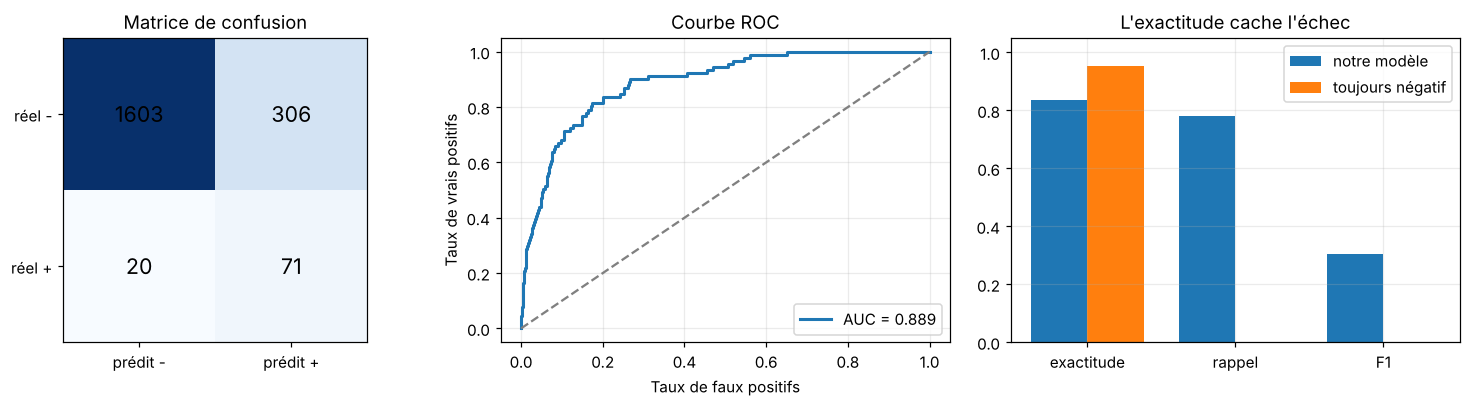

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
cm = confusion_matrix(y_true, y_pred)
ax[0].imshow(cm, cmap='Blues'); ax[0].grid(False)
for (i, j), v in np.ndenumerate(cm): ax[0].text(j, i, v, ha='center', va='center', fontsize=14)
ax[0].set_xticks([0, 1], ['prédit -', 'prédit +']); ax[0].set_yticks([0, 1], ['réel -', 'réel +']); ax[0].set_title('Matrice de confusion')
fpr, tpr, _ = roc_curve(y_true, scores)
ax[1].plot(fpr, tpr, lw=2, label=f'AUC = {roc_auc_score(y_true, scores):.3f}'); ax[1].plot([0, 1], [0, 1], '--', c='gray')
ax[1].set_xlabel('Taux de faux positifs'); ax[1].set_ylabel('Taux de vrais positifs'); ax[1].set_title('Courbe ROC'); ax[1].legend()
names = ['accuracy', 'recall', 'f1']; w = .38; x = np.arange(3)
ax[2].bar(x - w / 2, [m[k] for k in names], w, label='notre modèle'); ax[2].bar(x + w / 2, [lazy[k] for k in names], w, label='toujours négatif')
ax[2].set_xticks(x, ['exactitude', 'rappel', 'F1']); ax[2].set_ylim(0, 1.05); ax[2].set_title("L'exactitude cache l'échec"); ax[2].legend()
plt.tight_layout(); plt.show()

### 🔬 RÉEL : une régression logistique sur le jeu *digits* (10 classes)
Métriques multiclasses : **macro** = moyenne simple sur les classes, **micro** = on cumule les comptes, **weighted** = moyenne pondérée par le nombre d'exemples de chaque classe.

              precision    recall  f1-score   support

           0      1.000     1.000     1.000        54
           1      0.885     0.982     0.931        55
           2      1.000     0.981     0.990        53
           3      0.981     0.964     0.972        55
           4      1.000     0.963     0.981        54
           5      0.946     0.964     0.955        55
           6      1.000     0.981     0.991        54
           7      0.982     1.000     0.991        54
           8      0.960     0.923     0.941        52
           9      0.981     0.963     0.972        54

    accuracy                          0.972       540
   macro avg      0.974     0.972     0.972       540
weighted avg      0.973     0.972     0.972       540

macro     P=0.974  R=0.972  F1=0.972
micro     P=0.972  R=0.972  F1=0.972
weighted  P=0.973  R=0.972  F1=0.972
ROC-AUC macro (un contre tous) : 0.9992


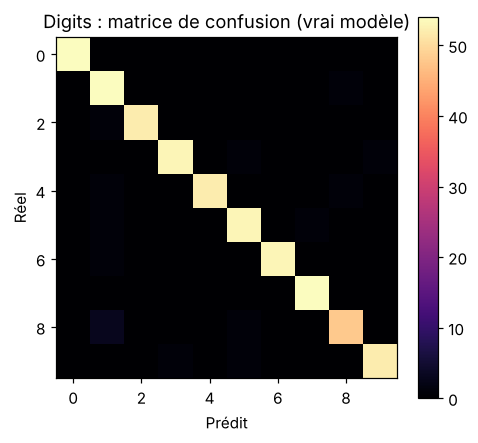

In [4]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

X, y = load_digits(return_X_y=True)
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=.3, stratify=y, random_state=0)
clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(Xtr, ytr)
pred, proba = clf.predict(Xte), clf.predict_proba(Xte)
print(classification_report(yte, pred, digits=3))
for avg in ('macro', 'micro', 'weighted'):
    print(f'{avg:9s} P={precision_score(yte, pred, average=avg):.3f}  R={recall_score(yte, pred, average=avg):.3f}  F1={f1_score(yte, pred, average=avg):.3f}')
print('ROC-AUC macro (un contre tous) :', round(roc_auc_score(yte, proba, multi_class='ovr', average='macro'), 4))

cmx = confusion_matrix(yte, pred)                      # F1 macro calculé à la main depuis la matrice de confusion
tp = np.diag(cmx); fp = cmx.sum(0) - tp; fn = cmx.sum(1) - tp
assert np.isclose((2 * tp / (2 * tp + fp + fn)).mean(), f1_score(yte, pred, average='macro'))
plt.figure(figsize=(5, 4.5)); plt.imshow(cmx, cmap='magma'); plt.grid(False); plt.colorbar()
plt.xlabel('Prédit'); plt.ylabel('Réel'); plt.title('Digits : matrice de confusion (vrai modèle)'); plt.show()

## 2. Détection d'objets
Une prédiction est un **VP** si sa classe est bonne et si IoU ≥ t avec une vérité terrain pas encore appariée (par confiance décroissante). Sinon, c'est un **FP**. Une vérité terrain non appariée est un **FN**.
`IoU = |A ∩ B| / |A ∪ B|` · `AP` = aire sous l'enveloppe de la courbe de précision (interpolation COCO à 101 points) · `mAP` = moyenne de l'AP sur les classes · `AP50:95` = moyenne sur les IoU 0,50 ; 0,55 ; … ; 0,95.

In [5]:
def box_iou(a, b):                        # boîtes au format [x1, y1, x2, y2]
    iw = max(0, min(a[2], b[2]) - max(a[0], b[0])); ih = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = iw * ih; area = lambda r: (r[2] - r[0]) * (r[3] - r[1])
    union = area(a) + area(b) - inter
    return inter / union if union > 0 else 0.0

assert box_iou([0, 0, 10, 10], [0, 0, 10, 10]) == 1 and box_iou([0, 0, 10, 10], [20, 20, 30, 30]) == 0
assert np.isclose(box_iou([0, 0, 10, 10], [5, 0, 15, 10]), 1 / 3)       # 50 / 150

IOU_THRS = np.round(np.arange(0.5, 0.96, 0.05), 2)

def match(preds, gts, iou_fn, thr):
    """Appariement glouton pour UNE classe. Renvoie les indicateurs VP, triés par score décroissant."""
    matched, tp = set(), []
    for p in sorted(preds, key=lambda p: -p['score']):
        best, bj = -1.0, -1
        for j, g in enumerate(gts):
            if g['img'] != p['img'] or j in matched: continue
            v = iou_fn(p['obj'], g['obj'])
            if v >= thr and v > best: best, bj = v, j
        if bj >= 0: matched.add(bj)
        tp.append(1 if bj >= 0 else 0)
    return np.array(tp, dtype=float)

def pr_curve(tp, n_gt):
    tpc, fpc = np.cumsum(tp), np.cumsum(1 - tp)
    return tpc / n_gt, tpc / np.maximum(tpc + fpc, 1e-12)

def average_precision(rec, prec):
    if len(rec) == 0: return 0.0
    env = np.maximum.accumulate(prec[::-1])[::-1]            # enveloppe de la précision
    idx = np.searchsorted(rec, np.linspace(0, 1, 101), side='left')
    return float(np.mean([env[i] if i < len(env) else 0.0 for i in idx]))

def evaluate_ap(preds, gts, iou_fn, thrs=IOU_THRS):
    classes = sorted({g['cls'] for g in gts}); ap = np.zeros((len(thrs), len(classes)))
    for ci, c in enumerate(classes):
        G = [g for g in gts if g['cls'] == c]; P = [p for p in preds if p['cls'] == c]
        for ti, t in enumerate(thrs):
            rec, prec = pr_curve(match(P, G, iou_fn, t), len(G)); ap[ti, ci] = average_precision(rec, prec)
    return dict(classes=classes, ap=ap, AP50=ap[0].mean(), AP75=ap[5].mean(), AP=ap.mean())

# test de cohérence : détections parfaites => AP = 1, aucune détection => AP = 0
_g = [dict(img=0, cls='a', obj=[0, 0, 10, 10])]
assert evaluate_ap([dict(img=0, cls='a', score=.9, obj=[0, 0, 10, 10])], _g, box_iou)['AP'] == 1.0
assert evaluate_ap([], _g, box_iou)['AP'] == 0.0

### 🧪 JOUET : 3 images, 2 classes, avec une bonne boîte, une boîte approximative, une mauvaise classe, un doublon et une fausse alarme

In [6]:
G_ = lambda i, c, b: dict(img=i, cls=c, obj=b)
D_ = lambda i, c, s, b: dict(img=i, cls=c, score=s, obj=b)
gts = [G_(0, 'cat', [10, 10, 60, 60]), G_(0, 'dog', [100, 20, 150, 80]), G_(1, 'cat', [20, 30, 90, 100]),
       G_(2, 'dog', [30, 30, 80, 90]), G_(2, 'cat', [120, 100, 170, 160])]
preds = [D_(0, 'cat', .95, [12, 12, 58, 64]), D_(0, 'dog', .90, [98, 25, 155, 85]), D_(0, 'cat', .30, [100, 100, 140, 140]),
         D_(1, 'cat', .80, [30, 40, 100, 110]), D_(1, 'dog', .40, [20, 30, 90, 100]),
         D_(2, 'dog', .85, [35, 35, 90, 95]), D_(2, 'cat', .70, [125, 105, 165, 150]), D_(2, 'cat', .60, [122, 102, 168, 158])]

# VP / FP / FN avec IoU = 0,5 et un seuil de score de 0,5
tpn = fpn = 0
for c in ('cat', 'dog'):
    P = [p for p in preds if p['cls'] == c and p['score'] >= .5]; G = [g for g in gts if g['cls'] == c]
    t = match(P, G, box_iou, .5); tpn += int(t.sum()); fpn += len(P) - int(t.sum())
fnn = len(gts) - tpn
print(f'VP={tpn} FP={fpn} FN={fnn}  précision={tpn / (tpn + fpn):.2f}  rappel={tpn / (tpn + fnn):.2f}')

res = evaluate_ap(preds, gts, box_iou)
print("AP50 par classe :", dict(zip(res['classes'], res['ap'][0].round(3))))
print(f"mAP50 (AP50) = {res['AP50']:.3f} | AP75 = {res['AP75']:.3f} | mAP50:95 (AP) = {res['AP']:.3f}")

VP=5 FP=1 FN=0  précision=0.83  rappel=1.00
AP50 par classe : {'cat': np.float64(1.0), 'dog': np.float64(1.0)}
mAP50 (AP50) = 1.000 | AP75 = 0.250 | mAP50:95 (AP) = 0.432


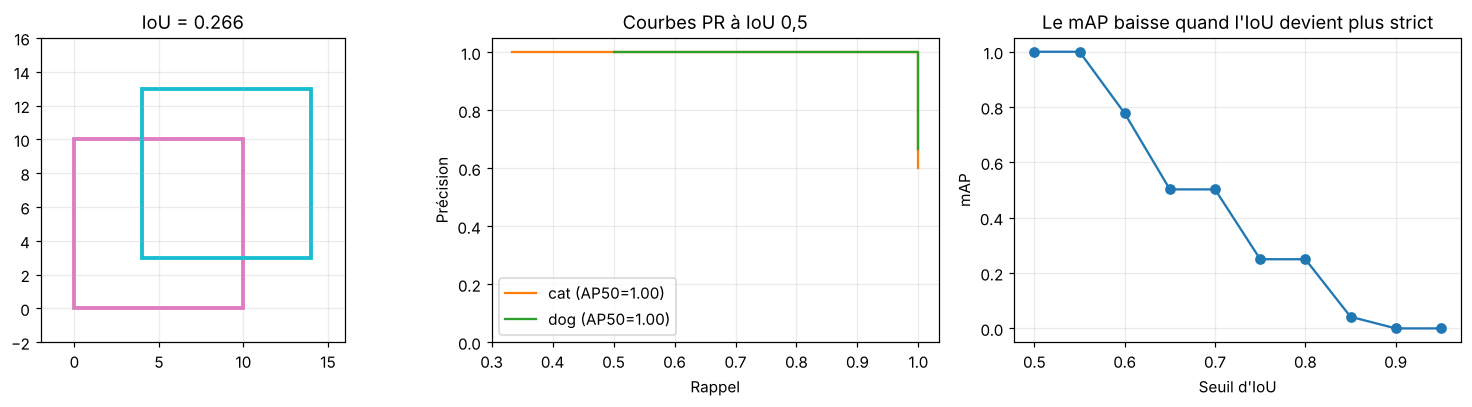

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
a_, b_ = [0, 0, 10, 10], [4, 3, 14, 13]                 # illustration de l'IoU
for r, c in ((a_, 'tab:pink'), (b_, 'tab:cyan')): ax[0].add_patch(plt.Rectangle(r[:2], r[2] - r[0], r[3] - r[1], fill=False, ec=c, lw=2.5))
ax[0].set_xlim(-2, 16); ax[0].set_ylim(-2, 16); ax[0].set_aspect('equal'); ax[0].set_title(f'IoU = {box_iou(a_, b_):.3f}')
for c, col in (('cat', 'tab:orange'), ('dog', 'tab:green')):
    P = [p for p in preds if p['cls'] == c]; G = [g for g in gts if g['cls'] == c]
    tp = match(P, G, box_iou, .5); rec, prec = pr_curve(tp, len(G))
    ax[1].step(rec, prec, where='post', c=col, label=f'{c} (AP50={average_precision(rec, prec):.2f})')
ax[1].set_xlabel('Rappel'); ax[1].set_ylabel('Précision'); ax[1].set_ylim(0, 1.05); ax[1].set_title('Courbes PR à IoU 0,5'); ax[1].legend()
ax[2].plot(IOU_THRS, res['ap'].mean(1), 'o-'); ax[2].set_xlabel("Seuil d'IoU"); ax[2].set_ylabel('mAP'); ax[2].set_title("Le mAP baisse quand l'IoU devient plus strict")
plt.tight_layout(); plt.show()

Vérification optionnelle avec l'implémentation de référence de type COCO dans `torchmetrics` (ignorée si le package n'est pas installé). De petites différences sont possibles, car les implémentations diffèrent sur la gestion des égalités et de l'interpolation.

In [8]:
try:
    import torch
    from torchmetrics.detection import MeanAveragePrecision
    labels = {'cat': 0, 'dog': 1}
    def to_t(items, img, score):
        its = [d for d in items if d['img'] == img]
        o = dict(boxes=torch.tensor([d['obj'] for d in its], dtype=torch.float32).reshape(-1, 4), labels=torch.tensor([labels[d['cls']] for d in its]))
        if score: o['scores'] = torch.tensor([d['score'] for d in its])
        return o
    mp = MeanAveragePrecision(iou_type='bbox'); mp.update([to_t(preds, i, True) for i in range(3)], [to_t(gts, i, False) for i in range(3)])
    r = mp.compute(); print('torchmetrics  map_50 =', float(r['map_50']), ' map =', float(r['map']))
    print('notre code    AP50   =', round(res['AP50'], 4), ' AP  =', round(res['AP'], 4))
except Exception as e:
    print('Vérification ignorée :', type(e).__name__)

Vérification ignorée : ModuleNotFoundError


## 3. Segmentation sémantique et d'instance
Tout se calcule à partir d'une matrice de confusion `cm[i, j]` = nombre de pixels de vraie classe *i* prédits comme *j* :
`PA = Σ cm[i,i] / Σ cm` · `IoU(c) = VP / (VP+FP+FN)` · `mIoU = moyenne_c IoU(c)` · `Dice(c) = 2VP / (2VP+FP+FN)`, donc `Dice = 2·IoU / (1+IoU)`.

In [9]:
def confusion_seg(gt, pred, n_classes, ignore_index=None):
    gt, pred = gt.ravel(), pred.ravel()
    if ignore_index is not None: k = gt != ignore_index; gt, pred = gt[k], pred[k]
    return np.bincount(n_classes * gt + pred, minlength=n_classes ** 2).reshape(n_classes, n_classes)

def seg_metrics(cm):
    tp = np.diag(cm).astype(float); g, p = cm.sum(1).astype(float), cm.sum(0).astype(float)
    with np.errstate(divide='ignore', invalid='ignore'):
        iou, dice = tp / (g + p - tp), 2 * tp / (g + p)     # NaN si une classe est absente des deux masques
    return dict(pixel_acc=tp.sum() / cm.sum(), iou=iou, miou=np.nanmean(iou), dice=dice, mdice=np.nanmean(dice))

H = W = 64; yy, xx = np.mgrid[:H, :W]
disc = lambda cy, cx, r: (yy - cy) ** 2 + (xx - cx) ** 2 <= r ** 2
gt = np.zeros((H, W), int); gt[disc(22, 22, 12)] = 1; gt[40:58, 36:58] = 2          # 0 = fond, 1 = disque, 2 = carré
pr = np.zeros((H, W), int); pr[disc(24, 25, 12)] = 1; pr[42:58, 34:55] = 2          # prédiction décalée et réduite
pr[rng.random((H, W)) < 0.01] = 0                                                       # un peu de bruit « sel »

### 🧪 JOUET : masques sémantiques, et pourquoi la précision pixel ne suffit pas

Précision pixel = 0.927 | IoU par classe = [0.913 0.674 0.701] | mIoU = 0.763 | Dice par classe = [0.955 0.805 0.824]
Prédiction 100 % fond : précision pixel = 0.796 mais mIoU = 0.265


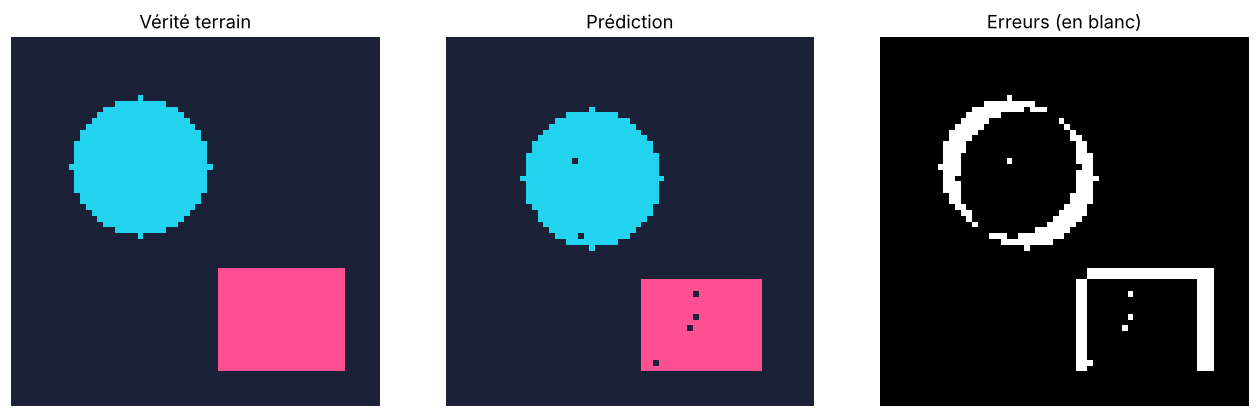

In [10]:
sm = seg_metrics(confusion_seg(gt, pr, 3))
print(f"Précision pixel = {sm['pixel_acc']:.3f} | IoU par classe = {sm['iou'].round(3)} | mIoU = {sm['miou']:.3f} | Dice par classe = {sm['dice'].round(3)}")
assert np.allclose(sm['dice'], 2 * sm['iou'] / (1 + sm['iou']))           # Dice = 2 IoU / (1 + IoU)

empty = seg_metrics(confusion_seg(gt, np.zeros_like(gt), 3))                # on ne prédit que du fond
print(f"Prédiction 100 % fond : précision pixel = {empty['pixel_acc']:.3f} mais mIoU = {empty['miou']:.3f}")

cmap = ListedColormap(['#1b2238', '#22d3ee', '#ff4f93'])
fig, ax = plt.subplots(1, 3, figsize=(12, 3.8))
for a, im, t in zip(ax, (gt, pr, gt != pr), ('Vérité terrain', 'Prédiction', 'Erreurs (en blanc)')):
    a.imshow(im, cmap='gray' if t.startswith('Err') else cmap, interpolation='nearest'); a.set_title(t); a.axis('off')
plt.tight_layout(); plt.show()

### 🧪 JOUET : segmentation d'instance et **Mask AP**
Même mécanique que pour la détection, mais l'IoU est calculé sur les **masques**. L'image 1 contient deux objets qui se touchent et que le modèle *fusionne* en un seul masque : les métriques sémantiques ne le verraient pas, le Mask AP si.

Mask AP50 = 0.505 | Mask AP75 = 0.505 | Mask AP50:95 = 0.329
IoU du masque fusionné avec chaque vraie instance : [np.float64(0.43), np.float64(0.43)]


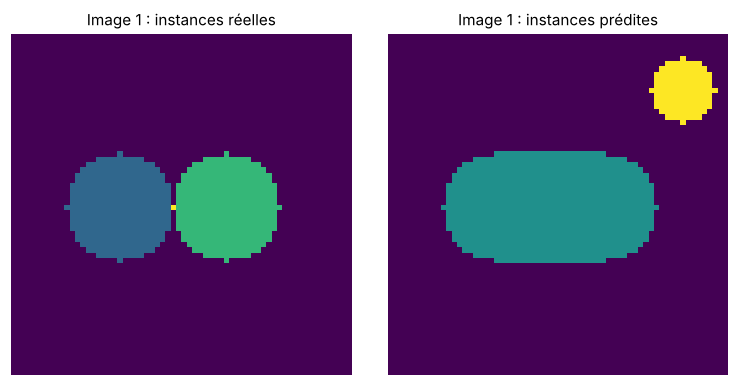

In [11]:
mask_iou = lambda a, b: (a & b).sum() / max((a | b).sum(), 1)
gts_i = [dict(img=0, cls='obj', obj=disc(20, 20, 10)), dict(img=0, cls='obj', obj=disc(44, 44, 10)),
         dict(img=1, cls='obj', obj=disc(32, 20, 10)), dict(img=1, cls='obj', obj=disc(32, 40, 10))]
merged = disc(32, 20, 10) | disc(32, 40, 10) | ((abs(yy - 32) <= 10) & (xx >= 20) & (xx <= 40))
preds_i = [dict(img=0, cls='obj', score=.9, obj=disc(21, 22, 10)), dict(img=0, cls='obj', score=.8, obj=disc(44, 43, 10)),
           dict(img=1, cls='obj', score=.7, obj=merged), dict(img=1, cls='obj', score=.3, obj=disc(10, 55, 6))]
ri = evaluate_ap(preds_i, gts_i, mask_iou)
print(f"Mask AP50 = {ri['AP50']:.3f} | Mask AP75 = {ri['AP75']:.3f} | Mask AP50:95 = {ri['AP']:.3f}")
print("IoU du masque fusionné avec chaque vraie instance :", [round(mask_iou(merged, g['obj']), 3) for g in gts_i[2:]])

lab = lambda items, img: sum((k + 1) * it['obj'] for k, it in enumerate(i for i in items if i['img'] == img))
fig, ax = plt.subplots(1, 2, figsize=(7, 3.5))
for a, items, t in zip(ax, (gts_i, preds_i), ('Image 1 : instances réelles', 'Image 1 : instances prédites')):
    a.imshow(lab(items, 1), cmap='viridis', interpolation='nearest'); a.set_title(t, fontsize=10); a.axis('off')
plt.tight_layout(); plt.show()

## Modèle de code : évaluer un vrai détecteur ou segmenteur
On utilise les mêmes fonctions avec de vraies prédictions. Il faut garder le même format de coordonnées et les mêmes identifiants de classes pour le modèle et la vérité terrain.

```python
# Segmentation (tout modèle qui renvoie une carte d'étiquettes entières par image)
cm = np.zeros((C, C), dtype=np.int64)
for image, gt_map in dataloader:
    cm += confusion_seg(gt_map, model_predict(image), C, ignore_index=255)
print(seg_metrics(cm))                  # on cumule sur le jeu de données, PUIS on calcule IoU/Dice

# Détection / segmentation d'instance : construire des listes de dictionnaires puis appeler evaluate_ap
# preds = [dict(img=i, cls=c, score=s, obj=boite_ou_masque), ...]; gts = [dict(img=i, cls=c, obj=boite_ou_masque), ...]
# evaluate_ap(preds, gts, box_iou)  ou  evaluate_ap(preds, gts, mask_iou)
```

## Résumé
| Tâche | Métriques programmées | Vérifiées avec | Données |
|---|---|---|---|
| Classification | Matrice de confusion, Exactitude, Précision, Rappel, F1, ROC-AUC, macro/micro | scikit-learn (assertions) | 🧪 jouet + 🔬 réel (digits) |
| Détection | IoU, VP/FP/FN, P/R, AP (101 points), mAP, AP50, AP75, AP50:95 | cas vérifiés à la main, torchmetrics en option | 🧪 jouet |
| Segmentation | Précision pixel, IoU, mIoU, Dice, Mask AP | identité Dice = 2·IoU/(1+IoU), cas limites | 🧪 jouet |